---
title: Models > Multinomial Logistic Regression (MNL)
jupyter: python3
---

<div class="alert alert-info">Estimate a multinomial logistic regression (MNL) for a categorical response with two or more levels</div>

<!-- pyrsm-teaching-note: roadmap -->
## Teaching Roadmap

A multinomial logistic regression explains which of several categories is chosen: the brand a shopper buys, the plan a customer signs up for. One level of the response is the **base level**; every other level gets its own intercept and its own coefficient for each explanatory variable, and every coefficient compares that level with the base level. The exponent of a coefficient, the **relative risk ratio (RRR)**, is the factor by which the odds of a level *relative to the base level* change for a one-unit increase in the variable.

Students should learn to (1) choose and name the base level, (2) interpret RRRs per level, (3) use predicted probabilities for what-if questions, (4) test groups of variables with a likelihood-ratio test, (5) check the data before trusting the coefficients, and (6) see how MNL relates to the conditional logit used for choice-based conjoint.

`rsm.model.mnl` matches R's `nnet::multinom` (used by radiant.model). In Radiant-AI the same analysis is *Model > Estimate > Multinomial logistic regression (MNL)*.

In [1]:
import polars as pl
import pyrsm as rsm

In [2]:
## setup pyrsm for autoreload
%reload_ext autoreload
%autoreload 2
%aimport pyrsm

## Example: Choice of ketchup

The `ketchup` data record 2,798 purchases by 300 households in a panel in Springfield, Missouri, over about two years (Jain, Vilcassim and Chintagunta, 1994):

- `id` — household identifier
- `choice` — the product bought: `heinz28`, `heinz32`, `heinz41` or `hunts32` (brand and package size in ounces)
- `price.x` — price of product `x` on that purchase occasion
- `disp.x` — was product `x` on display (yes, no)?
- `feat.x` — was product `x` featured in a newspaper ad (yes, no)?

The data are in **wide** format: one row per purchase, with the price, display and feature of every product in its own column. That is exactly the shape `mnl` needs.

In [3]:
ketchup = pl.read_parquet(
    "https://github.com/radiant-ai-hub/pyrsm/raw/refs/heads/main/examples/data/model/ketchup.parquet"
)
ketchup.head()

id,choice,price.heinz28,price.heinz32,price.heinz41,price.hunts32,disp.heinz28,disp.heinz32,disp.heinz41,disp.hunts32,feat.heinz28,feat.heinz32,feat.heinz41,feat.hunts32
enum,enum,f64,f64,f64,f64,enum,enum,enum,enum,enum,enum,enum,enum
"""C1""","""heinz28""",5.2000001,3.7,4.6,3.4000002,"""no""","""no""","""no""","""no""","""no""","""no""","""no""","""no"""
"""C1""","""heinz28""",5.2000001,4.3000001,4.6,4.4,"""no""","""no""","""no""","""no""","""no""","""no""","""no""","""no"""
"""C1""","""heinz28""",4.6,2.5,4.6,4.8,"""no""","""no""","""no""","""no""","""no""","""yes""","""no""","""no"""
"""C1""","""heinz28""",5.2000001,3.7,4.6,3.4000002,"""no""","""no""","""no""","""no""","""no""","""no""","""no""","""no"""
"""C1""","""heinz28""",4.6,3.0,4.6,4.8,"""no""","""no""","""no""","""no""","""yes""","""no""","""no""","""no"""


In [4]:
ketchup["choice"].value_counts(sort=True)

choice,count
enum,u32
"""heinz32""",1458
"""heinz28""",851
"""hunts32""",307
"""heinz41""",182


`heinz32` is bought most often, followed by `heinz28`; `hunts32` and `heinz41` are bought much less often.

## a. How do prices influence which product is bought?

Estimate the model with `heinz28` as the base level and the four prices as explanatory variables.

In [5]:
prices = ["price.heinz28", "price.heinz32", "price.heinz41", "price.hunts32"]
mnl = rsm.model.mnl({"ketchup": ketchup}, rvar="choice", lev="heinz28", evar=prices)
mnl.summary()

Multinomial logistic regression (MNL)
Data                 : ketchup
Response variable    : choice
Base level           : heinz28 in choice
Explanatory variables: price.heinz28, price.heinz32, price.heinz41, price.hunts32
Null hyp.: there is no effect of x on choice
Alt. hyp.: there is an effect of x on choice

┌─────────┬───────────────┬───────┬────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ level   ┆ index         ┆ RRR   ┆ RRR%   ┆ coefficient ┆ std.error ┆ z.value ┆ p.value ┆     │
╞═════════╪═══════════════╪═══════╪════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ heinz32 ┆ Intercept     ┆       ┆        ┆ 4.776       ┆ 0.74      ┆ 6.451   ┆ < .001  ┆ *** │
│ heinz32 ┆ price.heinz28 ┆ 3.0   ┆ 200.0% ┆ 1.099       ┆ 0.076     ┆ 14.44   ┆ < .001  ┆ *** │
│ heinz32 ┆ price.heinz32 ┆ 0.101 ┆ -89.9% ┆ -2.296      ┆ 0.135     ┆ -17.033 ┆ < .001  ┆ *** │
│ heinz32 ┆ price.heinz41 ┆ 0.686 ┆ -31.4% ┆ -0.377      ┆ 0.118     ┆ -3.182  ┆ 0.001   ┆ **  │
│ heinz3

Each row compares one product (`level`) with `heinz28`. The second row is the effect of `price.heinz28` on buying `heinz32` rather than `heinz28`: RRR = exp(1.099) = 3.000. A $1 higher price for heinz28 triples the odds of buying heinz32 instead, holding the other prices constant: the two are substitutes.

- `heinz32`, `price.heinz32`: RRR 0.101. A $1 higher price for heinz32 lowers the odds of heinz32 rather than heinz28 by 89.9%.
- `hunts32`, `price.heinz28`: RRR 3.602. A $1 higher price for heinz28 raises the odds of hunts32 rather than heinz28 by 260.2%.
- `hunts32`, `price.hunts32`: RRR 0.070, 93.0% lower odds.

The intercepts have no RRR: they are the log odds of each level relative to the base level when every price is 0.

McFadden's pseudo R-squared compares the model with one that predicts every purchase with the overall share of each product. The chi-squared test has 12 degrees of freedom: 15 coefficients minus the 3 intercepts of that null model.

## b. Which effects are clearly different from 1?

Relative risk ratios with 95% confidence intervals, on a log scale. Left of the dashed line lowers the odds of a level relative to `heinz28`, right of it raises them.

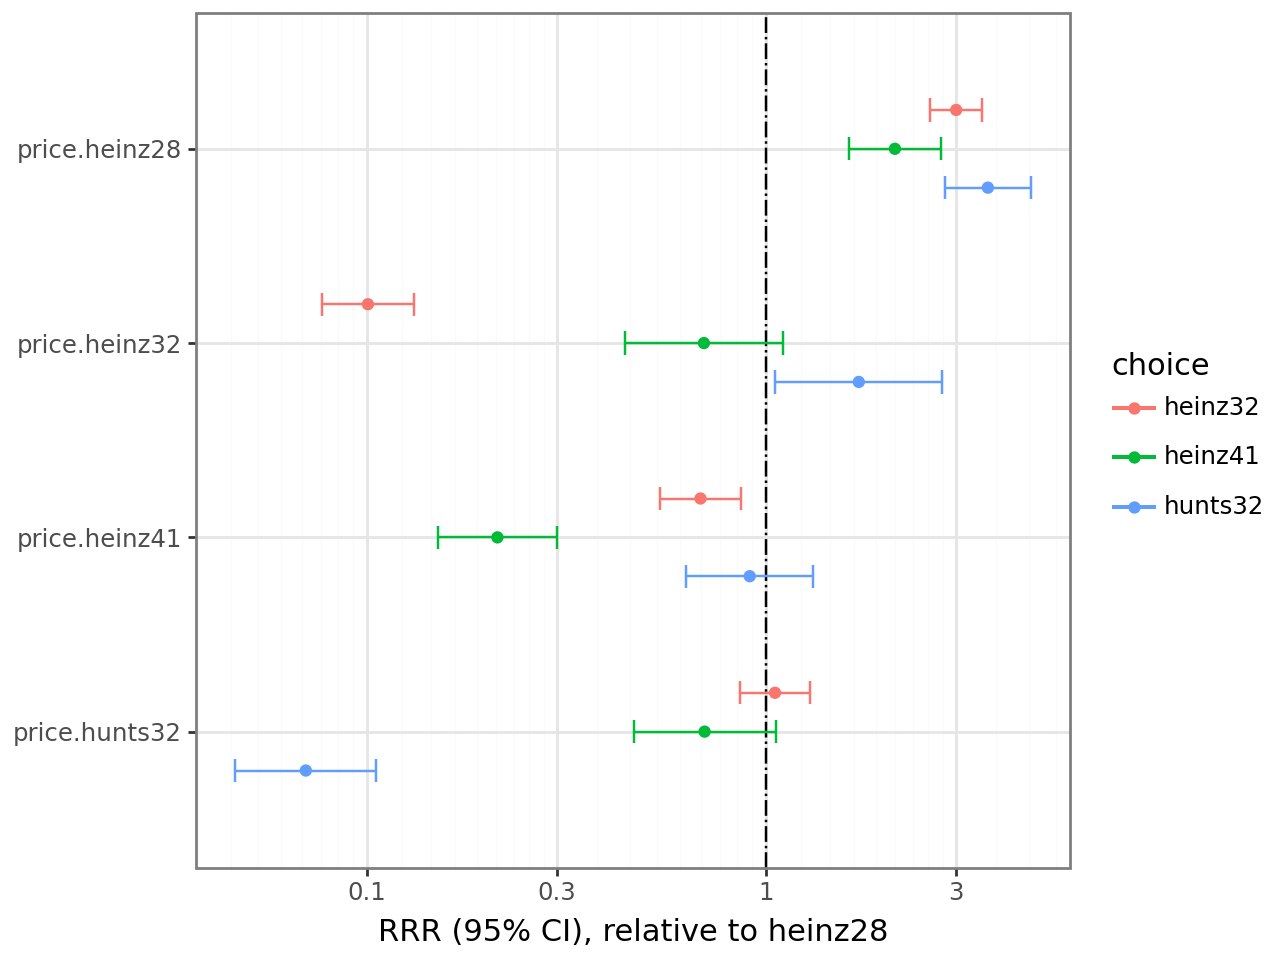

In [6]:
mnl.plot("coef")

A higher `price.heinz28` raises the odds of all three other products; each product's own price lowers its odds; and `hunts32` is the only product whose odds rise with `price.heinz32`.

The tables behind the plot:

In [7]:
mnl.summary(main=False, fit=False, rrr=True)


Relative risk ratios:

┌─────────┬───────────────┬───────┬───────┬───────┐
│ level   ┆ index         ┆ RRR   ┆ 2.5%  ┆ 97.5% │
╞═════════╪═══════════════╪═══════╪═══════╪═══════╡
│ heinz32 ┆ price.heinz28 ┆ 3.0   ┆ 2.585 ┆ 3.483 │
│ heinz32 ┆ price.heinz32 ┆ 0.101 ┆ 0.077 ┆ 0.131 │
│ heinz32 ┆ price.heinz41 ┆ 0.686 ┆ 0.544 ┆ 0.865 │
│ heinz32 ┆ price.hunts32 ┆ 1.055 ┆ 0.862 ┆ 1.291 │
│ heinz41 ┆ price.heinz28 ┆ 2.106 ┆ 1.614 ┆ 2.749 │
│ heinz41 ┆ price.heinz32 ┆ 0.7   ┆ 0.444 ┆ 1.102 │
│ heinz41 ┆ price.heinz41 ┆ 0.212 ┆ 0.151 ┆ 0.299 │
│ heinz41 ┆ price.hunts32 ┆ 0.702 ┆ 0.466 ┆ 1.059 │
│ hunts32 ┆ price.heinz28 ┆ 3.603 ┆ 2.816 ┆ 4.608 │
│ hunts32 ┆ price.heinz32 ┆ 1.71  ┆ 1.057 ┆ 2.767 │
│ hunts32 ┆ price.heinz41 ┆ 0.911 ┆ 0.631 ┆ 1.316 │
│ hunts32 ┆ price.hunts32 ┆ 0.07  ┆ 0.047 ┆ 0.106 │
└─────────┴───────────────┴───────┴───────┴───────┘


## c. Predicted probabilities

Probabilities are easier to explain than RRRs. Vary `price.heinz28` with the other prices at their mean; every row's four probabilities add to 1.

In [8]:
pred = mnl.predict(cmd={"price.heinz28": [3.4, 3.6, 3.8, 4.0, 4.2, 4.4, 4.6, 4.8, 5.0, 5.2]}, dec=3)
pred

price.heinz28,price.heinz32,price.heinz41,price.hunts32,heinz28,heinz32,heinz41,hunts32
f64,f64,f64,f64,f64,f64,f64,f64
3.4,3.143495,4.634203,3.355468,0.517,0.393,0.057,0.032
3.6,3.143495,4.634203,3.355468,0.464,0.439,0.06,0.038
3.8,3.143495,4.634203,3.355468,0.411,0.484,0.062,0.043
4.0,3.143495,4.634203,3.355468,0.36,0.529,0.063,0.049
4.2,3.143495,4.634203,3.355468,0.312,0.571,0.063,0.055
4.4,3.143495,4.634203,3.355468,0.268,0.609,0.063,0.06
4.6,3.143495,4.634203,3.355468,0.227,0.645,0.062,0.066
4.8,3.143495,4.634203,3.355468,0.191,0.676,0.06,0.072
5.0,3.143495,4.634203,3.355468,0.16,0.704,0.058,0.078


As `price.heinz28` rises from $3.40 to $5.20, its own probability drops from 51.7% to 13.3% and `heinz32` gains most (39.3% to 72.8%). `hunts32` rises from 3.2% to 8.4%: fewer percentage points, but a larger change relative to where it started.

`plot("pred")` draws such curves for every explanatory variable, each varied over the 2.5th to 97.5th percentile of the data:

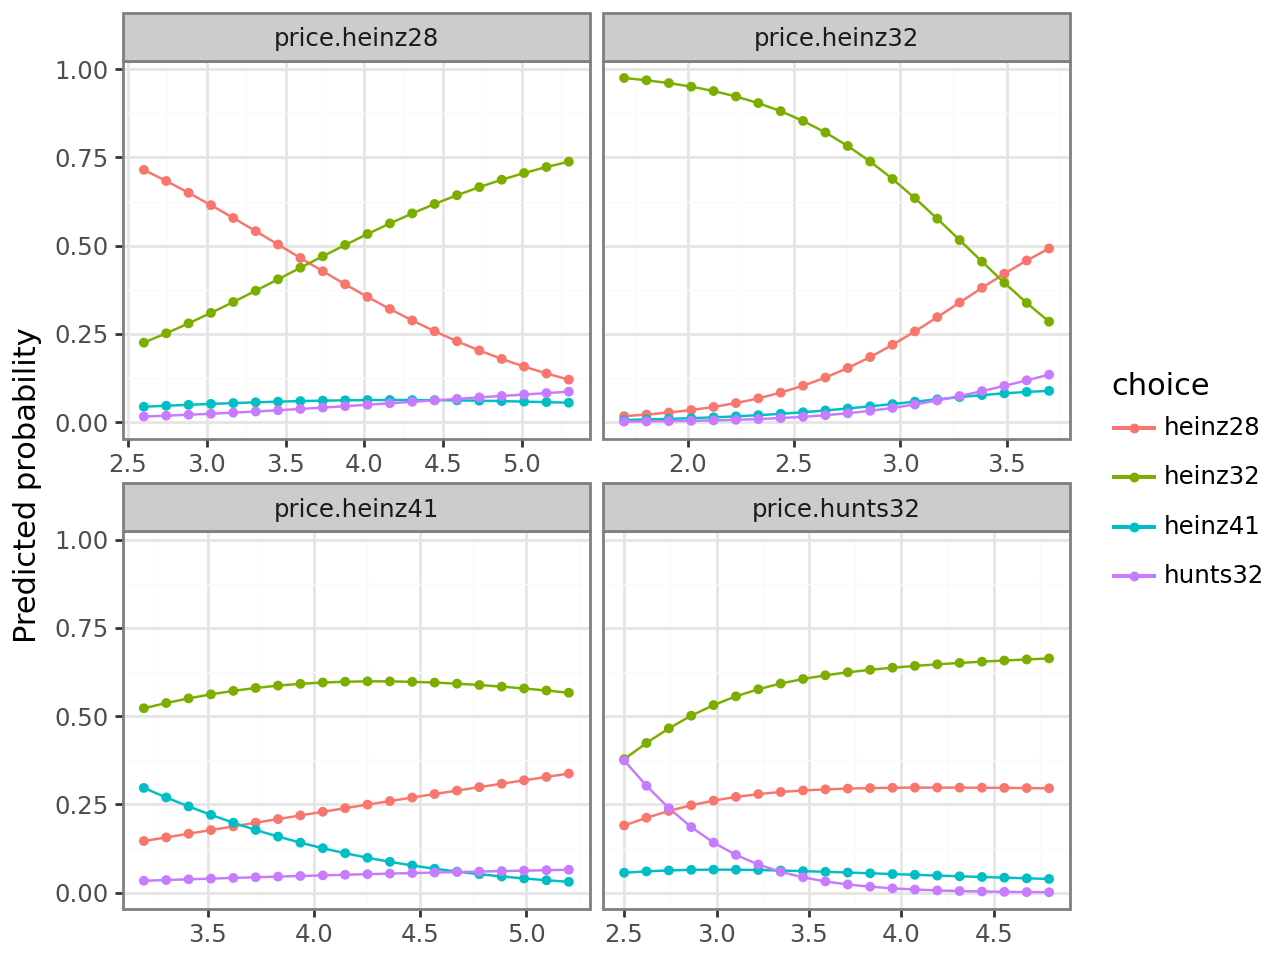

In [9]:
mnl.plot("pred")

To plot a prediction table yourself, put it in long form, one row per level:

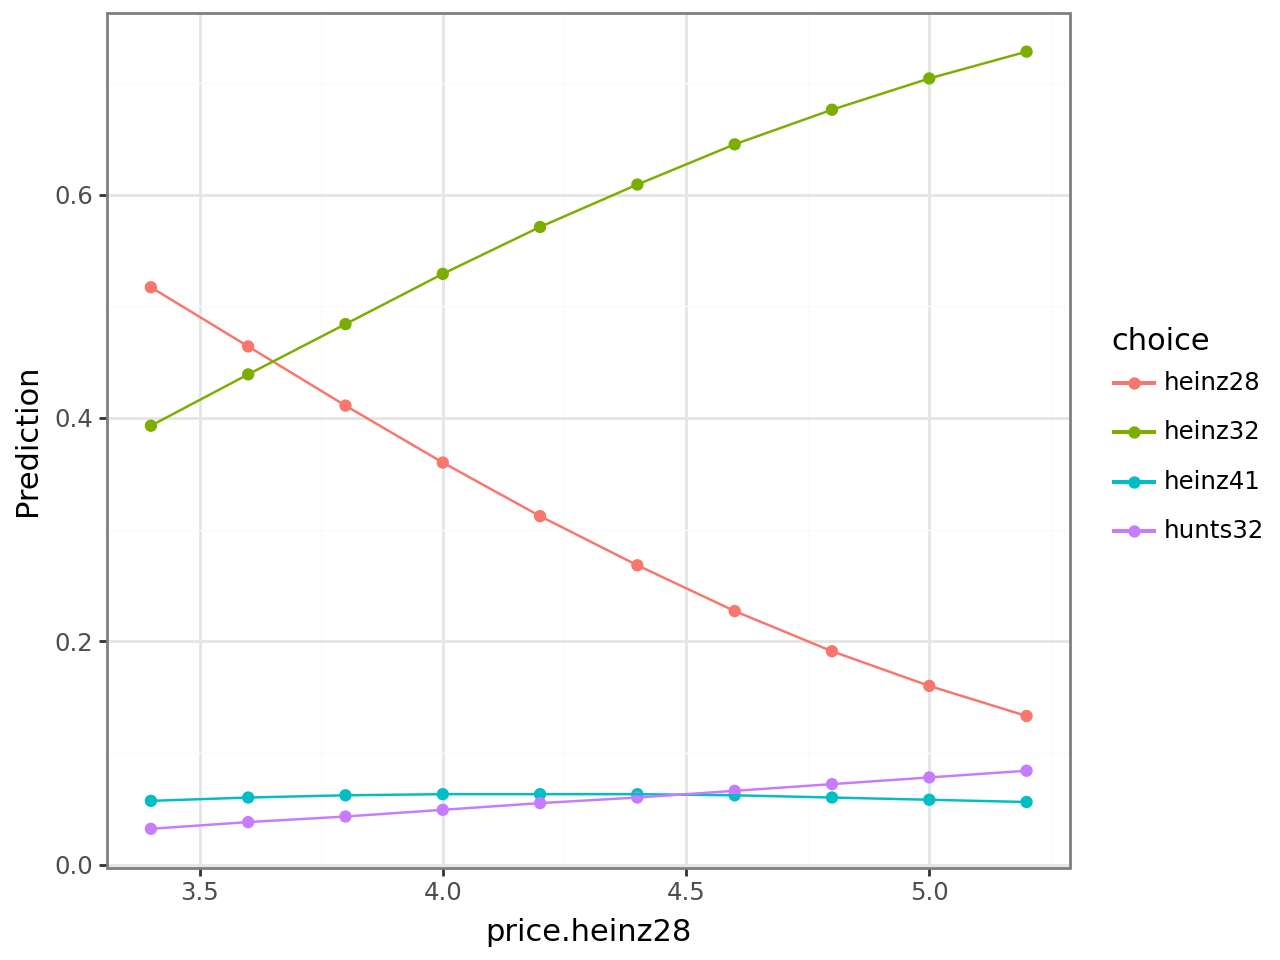

In [10]:
levels = ["heinz28", "heinz32", "heinz41", "hunts32"]
pred_long = pred.unpivot(on=levels, index=prices, variable_name="choice", value_name="prediction")
rsm.model.plot_predictions(pred_long, xvar="price.heinz28", color="choice")

## d. Do displays matter once prices are in the model?

Add the four display variables and test them together with a likelihood-ratio test (`test=`): the model without them is Model 1.

In [11]:
disps = ["disp.heinz28", "disp.heinz32", "disp.heinz41", "disp.hunts32"]
mnl2 = rsm.model.mnl({"ketchup": ketchup}, rvar="choice", lev="heinz28", evar=prices + disps)
mnl2.summary(main=False, test=disps)


Pseudo R-squared (McFadden): 0.217
Pseudo R-squared (McFadden adjusted): 0.208
Log-likelihood: -2458.700, AIC: 4971.401, BIC: 5131.691
Chi-squared: 1360.675, df(24), p.value < .001
Nr obs: 2,798

Model 1: choice ~ price.heinz28 + price.heinz32 + price.heinz41 + price.hunts32
Model 2: choice ~ price.heinz28 + price.heinz32 + price.heinz41 + price.hunts32 + disp.heinz28 + disp.heinz32 + disp.heinz41 + disp.hunts32
Pseudo R-squared, Model 1 vs 2: 0.200 vs 0.217
Chi-squared: 105.022 df (12), p.value < .001


Chi-squared 105.0 with 12 degrees of freedom (4 variables × 3 levels): displays matter. A display for `heinz28`, for example, lowers the odds of each other product relative to heinz28:

In [12]:
mnl2.coef.filter(pl.col("index") == "disp.heinz28[yes]").select("level", "index", "RRR", "p.value")

level,index,RRR,p.value
str,str,f64,f64
"""heinz32""","""disp.heinz28[yes]""",0.29458,1.3872e-8
"""heinz41""","""disp.heinz28[yes]""",0.286421,0.002284
"""hunts32""","""disp.heinz28[yes]""",0.419035,0.003303


## e. How well does the model classify purchases?

The confusion matrix shows the most likely product (rows) against the product bought (columns).

In [13]:
mnl.summary(main=False, fit=False, confusion=True)


Confusion matrix (rows: predicted, columns: actual):

┌───────────┬─────────┬─────────┬─────────┬─────────┐
│ predicted ┆ heinz28 ┆ heinz32 ┆ heinz41 ┆ hunts32 │
╞═══════════╪═════════╪═════════╪═════════╪═════════╡
│ heinz28   ┆ 422     ┆ 215     ┆ 56      ┆ 61      │
│ heinz32   ┆ 403     ┆ 1213    ┆ 112     ┆ 125     │
│ heinz41   ┆ 0       ┆ 1       ┆ 10      ┆ 0       │
│ hunts32   ┆ 26      ┆ 29      ┆ 4       ┆ 121     │
└───────────┴─────────┴─────────┴─────────┴─────────┘

Misclassification error: 36.883%


36.9% of the purchases are misclassified, and `heinz41` is the most likely product for only 11 purchases. A rare level is seldom the *most likely* one, even when its probability is predicted well, so judge a multinomial model by its probabilities and not by the confusion matrix alone.

## Check the data first

The prices include values that look like data errors:

In [14]:
ketchup.select(prices).describe()

statistic,price.heinz28,price.heinz32,price.heinz41,price.hunts32
str,f64,f64,f64,f64
"""count""",2798.0,2798.0,2798.0,2798.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",4.316154,3.143495,4.634203,3.355468
"""std""",0.750671,0.546938,0.451612,0.530686
"""min""",0.1,0.3,2.0,0.3
"""25%""",3.9,3.0,4.4,3.1
"""50%""",4.3000001,3.2000002,4.6,3.4000002
"""75%""",4.8,3.5999998,5.0000001,3.5999998
"""max""",12.0,4.3000001,7.2,8.6999997


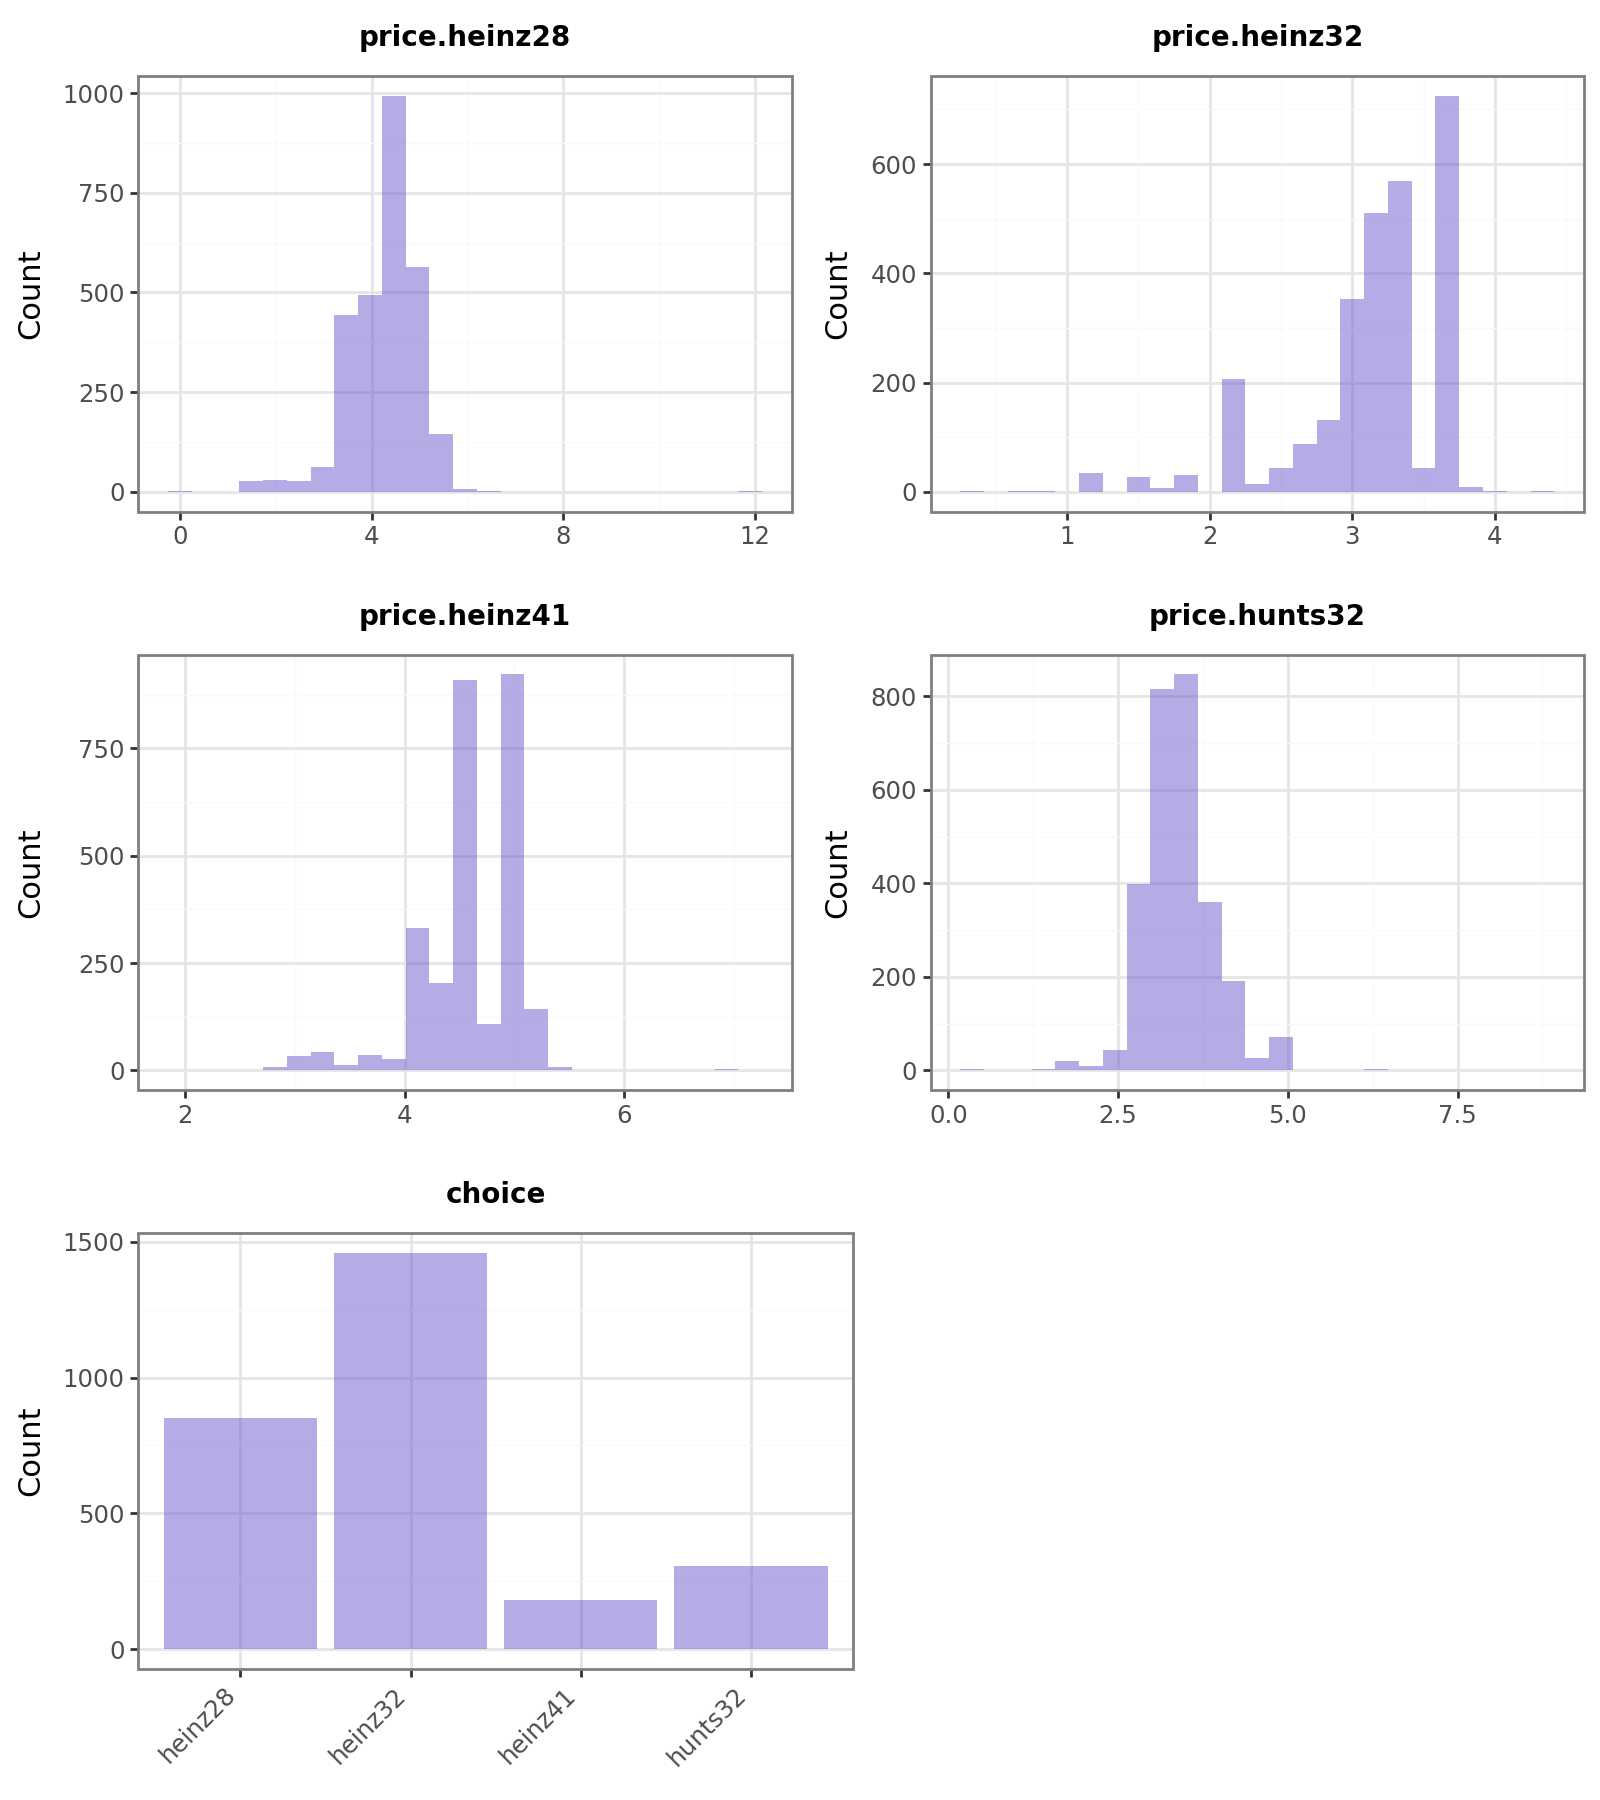

In [15]:
mnl.plot("dist")

The middle half of the prices lies between about $3 and $5, but `price.heinz28` runs from $0.10 to $12.00 and `price.hunts32` up to $8.70. Re-estimate without the extreme values (`data_filter`; column names with dots work in filters) and compare:

In [16]:
mnl_trim = rsm.model.mnl(
    {"ketchup": ketchup},
    rvar="choice",
    lev="heinz28",
    evar=prices,
    data_filter="price.heinz28 >= 2 and price.heinz28 <= 7 and price.hunts32 <= 7",
)
mnl.coef.select("level", "index", pl.col("RRR").alias("RRR_all")).join(
    mnl_trim.coef.select("level", "index", pl.col("RRR").alias("RRR_trimmed")),
    on=["level", "index"],
).filter(pl.col("index") != "Intercept")

level,index,RRR_all,RRR_trimmed
str,str,f64,f64
"""heinz32""","""price.heinz28""",3.000266,2.757078
"""heinz32""","""price.heinz32""",0.100632,0.101315
"""heinz32""","""price.heinz41""",0.685912,0.685017
"""heinz32""","""price.hunts32""",1.054643,1.071386
"""heinz41""","""price.heinz28""",2.106343,1.923872
"""heinz41""","""price.heinz32""",0.699524,0.692696
"""heinz41""","""price.heinz41""",0.212465,0.214897
"""heinz41""","""price.hunts32""",0.702377,0.729735
"""hunts32""","""price.heinz28""",3.602518,3.41927


Without the extreme prices the RRRs of `price.heinz28` move most (3.00 to 2.76 for heinz32, 2.11 to 1.92 for heinz41); the others barely change, so the conclusions hold.

Prices may also be endogenous: if stores cut a price when demand is low, the estimated price effect mixes the two. Without an experiment, read the price effects as associations.

## Standardized RRRs

With `standardize=True` every numeric explanatory variable X is replaced by (X − mean(X)) / (2 × sd(X)) (Gelman, 2008), so RRRs of variables on different scales can be compared:

In [17]:
mnl_std = rsm.model.mnl({"ketchup": ketchup}, rvar="choice", lev="heinz28", evar=prices, standardize=True)
mnl_std.coef.filter(pl.col("level") == "heinz32").select("index", "RRR")

index,RRR
str,f64
"""Intercept""",null
"""price.heinz28""",5.204513
"""price.heinz32""",0.081118
"""price.heinz41""",0.7114
"""price.hunts32""",1.058092


## The base level does not change the predictions

Every coefficient depends on the base level, but the model is the same: the predicted probabilities do not change.

In [18]:
mnl_hunts = rsm.model.mnl({"ketchup": ketchup}, rvar="choice", lev="hunts32", evar=prices)
pl.DataFrame(
    {
        "heinz32 (base heinz28)": mnl.predict(ketchup.head(5))["heinz32"],
        "heinz32 (base hunts32)": mnl_hunts.predict(ketchup.head(5))["heinz32"],
    }
)

heinz32 (base heinz28),heinz32 (base hunts32)
f64,f64
0.422854,0.422854
0.244081,0.244081
0.917655,0.917655
0.422854,0.422854
0.78432,0.78432


## MNL and the conditional logit

MNL gives every product its own coefficient for every variable: 13 variables × 3 levels + 3 intercepts = 39 coefficients for prices, displays and features. When the variables describe the *alternatives* (each product's own price, display and feature), a more parsimonious model has **one** price coefficient, one display and one feature coefficient for all products, plus a constant per brand. That is the conditional logit `rsm.multivariate.conjoint_choice` estimates for choice-based conjoint, and it needs the data in **long** format: one row per product per purchase.

In [19]:
brands = ["heinz28", "heinz32", "heinz41", "hunts32"]
purchases = ketchup.with_row_index("occasion", offset=1)
ketchup_long = (
    pl.concat(
        [
            purchases.select(
                "occasion",
                "id",
                "choice",
                pl.lit(b).alias("brand"),
                pl.col(f"price.{b}").alias("price"),
                pl.col(f"disp.{b}").alias("disp"),
                pl.col(f"feat.{b}").alias("feat"),
            )
            for b in brands
        ]
    )
    .with_columns(
        pl.col("brand").cast(pl.Enum(brands)),
        (pl.col("choice").cast(pl.Utf8) == pl.col("brand").cast(pl.Utf8)).cast(pl.Int8).alias("chosen"),
    )
    .sort("occasion", "brand")
)
ketchup_long.head(8)

occasion,id,choice,brand,price,disp,feat,chosen
u32,enum,enum,enum,f64,enum,enum,i8
1,"""C1""","""heinz28""","""heinz28""",5.2000001,"""no""","""no""",1
1,"""C1""","""heinz28""","""heinz32""",3.7,"""no""","""no""",0
1,"""C1""","""heinz28""","""heinz41""",4.6,"""no""","""no""",0
1,"""C1""","""heinz28""","""hunts32""",3.4000002,"""no""","""no""",0
2,"""C1""","""heinz28""","""heinz28""",5.2000001,"""no""","""no""",1
2,"""C1""","""heinz28""","""heinz32""",4.3000001,"""no""","""no""",0
2,"""C1""","""heinz28""","""heinz41""",4.6,"""no""","""no""",0
2,"""C1""","""heinz28""","""hunts32""",4.4,"""no""","""no""",0


In [20]:
clogit = rsm.multivariate.conjoint_choice(
    {"ketchup_long": ketchup_long},
    rvar="chosen",
    lev="1",
    evar=["brand", "price", "disp", "feat"],
    id="occasion",
    alt="brand",
)
clogit.summary()

Conjoint choice model (conditional logit)
Data                 : ketchup_long
Response variable    : chosen
Level                : 1
Choice task id       : occasion
Alternative id       : brand
Explanatory variables: brand, price, disp, feat
Null hyp.: There is no effect of x on the choice of chosen
Alt. hyp.: There is an effect of x on the choice of chosen

┌────────────────┬───────┬────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index          ┆ OR    ┆ OR%    ┆ coefficient ┆ std.error ┆ z.value ┆ p.value ┆     │
╞════════════════╪═══════╪════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ brand[heinz32] ┆ 0.397 ┆ -60.3% ┆ -0.925      ┆ 0.077     ┆ -11.976 ┆ < .001  ┆ *** │
│ brand[heinz41] ┆ 0.342 ┆ -65.8% ┆ -1.072      ┆ 0.087     ┆ -12.28  ┆ < .001  ┆ *** │
│ brand[hunts32] ┆ 0.088 ┆ -91.2% ┆ -2.426      ┆ 0.096     ┆ -25.221 ┆ < .001  ┆ *** │
│ price          ┆ 0.246 ┆ -75.4% ┆ -1.402      ┆ 0.058     ┆ -24.183 ┆ < .001  ┆ *** │
│ disp[yes]      ┆ 2.4 

One price coefficient (−1.40: a $1 higher price lowers a product's odds of being chosen by 75%, whichever product it is), one display and one feature effect, and three brand constants relative to `heinz28`: 6 coefficients instead of 39. Compare the fit with the full MNL (prices, displays and features) by log-likelihood and AIC; pseudo R-squared is not comparable, because the two use different null models:

In [21]:
feats = ["feat.heinz28", "feat.heinz32", "feat.heinz41", "feat.hunts32"]
mnl_all = rsm.model.mnl({"ketchup": ketchup}, rvar="choice", lev="heinz28", evar=prices + disps + feats)
pl.DataFrame(
    {
        "model": ["MNL (39 coefficients)", "Conditional logit (6 coefficients)"],
        "log-likelihood": [mnl_all.fit_stats["loglik"], clogit.fit_stats["loglik"]],
        "AIC": [mnl_all.fit_stats["AIC"], clogit.fit_stats["AIC"]],
    }
)

model,log-likelihood,AIC
str,f64,f64
"""MNL (39 coefficients)""",-2414.281946,4906.563892
"""Conditional logit (6 coefficients)""",-2517.87725,5047.754499


The MNL fits better (it is more flexible: each product reacts differently to each price) and its AIC is lower, so the extra coefficients are worth it here. The conditional logit is easier to communicate and can predict for a product with a new price, display or feature combination. Both models are estimated by the same engine in pyrsm (`pyrsm._logit`): an MNL *is* a conditional logit on a long design with level-specific intercepts and every variable interacted with the level indicators.

## Discussion Prompts

- Why must every interpretation of an MNL coefficient name the base level?
- `heinz32` gains most when `heinz28`'s price rises. What does that say about which products compete most closely?
- Which levels would you expect the IIA assumption to treat unrealistically in this market?
- When would you prefer the conditional logit over the MNL for a pricing decision?

Source: Jain, D. C., Vilcassim, N. J. and Chintagunta, P. K. (1994), "A random-coefficients logit brand-choice model applied to panel data", *Journal of Business & Economic Statistics*, 12(3), 317–328.